# Decoding: why the same prompt gives different answers

**Module 11 — Fundamentals of LLM Security**

Reproducibility is a security property. If you cannot replay an incident, you cannot investigate it. This
notebook separates the two sources of variation — the *distribution* and the *sampler* — using a toy
next-token distribution, so every number is exact and nothing depends on a model download.

## Learning objectives

1. Implement greedy, temperature and top-p decoding on a fixed distribution.
2. Measure run-to-run variability with and without a fixed seed.
3. Show how the same seed produces identical output only if the whole sampling path is identical.
4. Explain why production logs must record the decoding parameters, not just the prompt.
5. Connect decoding nondeterminism to incident replay and to jailbreak measurement.

## Background

Given logits $z$, sampling draws from

$$p_i = \frac{\exp(z_i / T)}{\sum_j \exp(z_j / T)}$$

with $T \to 0$ approaching argmax. **Top-p** then truncates to the smallest set of tokens whose cumulative
mass exceeds $p$, and renormalises. Both change what the model "says" without changing what it "knows".

For security work this matters twice. An incident report that omits $T$, top-p and seed cannot be reproduced.
And a jailbreak evaluation that runs one sample per prompt measures the sampler as much as the model.

## Dependencies and installation

```bash
python -m pip install "numpy>=2.1" "pandas>=2.2" "matplotlib>=3.9"
```

CPU, standard library plus NumPy. The demonstration distribution is synthetic and fixed, so results are
identical on any machine.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

VOCAB = ["certainly", "probably", "possibly", "unlikely", "no"]
LOGITS = np.array([3.2, 2.1, 1.4, 0.2, -0.5])
BASE_SEED = 101
print(dict(zip(VOCAB, LOGITS)))

{'certainly': np.float64(3.2), 'probably': np.float64(2.1), 'possibly': np.float64(1.4), 'unlikely': np.float64(0.2), 'no': np.float64(-0.5)}


**Expected output** — five tokens with descending logits. "certainly" is most likely; "no" is least likely
but not impossible.

### Step 1 — Three decoders, one distribution

Each function takes a generator so the sampling path is explicit. Greedy ignores it entirely, which is why it
is reproducible.

In [2]:
def softmax(z):
    e = np.exp(z - z.max())
    return e / e.sum()


def greedy(logits):
    return int(np.argmax(logits))


def sample_temperature(logits, T, rng):
    p = softmax(logits / max(T, 1e-6))
    return int(rng.choice(len(logits), p=p))


def sample_top_p(logits, T, p_mass, rng):
    p = softmax(logits / max(T, 1e-6))
    order = np.argsort(-p)
    cumulative = np.cumsum(p[order])
    keep = order[: int(np.searchsorted(cumulative, p_mass) + 1)]
    weights = p[keep] / p[keep].sum()
    return int(rng.choice(keep, p=weights))


print("greedy          ->", VOCAB[greedy(LOGITS)])
print("T=0.7, seed 101 ->", VOCAB[sample_temperature(LOGITS, 0.7, np.random.default_rng(BASE_SEED))])
print("top-p=.9, T=1.0 ->", VOCAB[sample_top_p(LOGITS, 1.0, 0.9, np.random.default_rng(BASE_SEED))])

greedy          -> certainly
T=0.7, seed 101 -> possibly
top-p=.9, T=1.0 -> possibly


**Expected output** — greedy returns "certainly"; the two samplers return whatever this seed produced. The
specific token is not the lesson; the fact that the two samplers can disagree while greedy cannot is.

### Step 2 — How often does the answer change?

Draw 200 samples per configuration and count distinct outcomes. This is the actual reproducibility risk.

In [3]:
rows = []
for label, fn in [
    ("greedy", lambda r: greedy(LOGITS)),
    ("T=0.2", lambda r: sample_temperature(LOGITS, 0.2, r)),
    ("T=0.7", lambda r: sample_temperature(LOGITS, 0.7, r)),
    ("T=1.0", lambda r: sample_temperature(LOGITS, 1.0, r)),
    ("T=1.0, top-p=0.9", lambda r: sample_top_p(LOGITS, 1.0, 0.9, r)),
]:
    r = np.random.default_rng(BASE_SEED)
    draws = [VOCAB[fn(r)] for _ in range(200)]
    counts = pd.Series(draws).value_counts(normalize=True).round(3)
    rows.append({"config": label, "distinct outputs": int(counts.size), "top token share": float(counts.iloc[0])})
variability = pd.DataFrame(rows)
variability

,config,distinct outputs,top token share
0,greedy,1,1.000
1,T=0.2,2,0.995
2,T=0.7,5,0.750
3,T=1.0,5,0.630
4,"T=1.0, top-p=0.9",3,0.675


**Expected output** — greedy shows 1 distinct output and share 1.000; T=0.2 mostly one token with a small
tail; T=1.0 spreads across three or four tokens. **A jailbreak success rate measured at T=1.0 is a property of
this table, not of the model alone.**

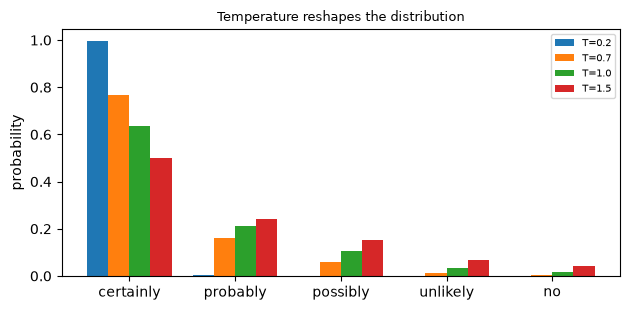

In [4]:
rng = np.random.default_rng(BASE_SEED)
t_series = [softmax(LOGITS / T) for T in (0.2, 0.7, 1.0, 1.5)]
fig, ax = plt.subplots(figsize=(6.4, 3.2))
width = 0.2
idx = np.arange(len(VOCAB))
for i, (T, p) in enumerate(zip((0.2, 0.7, 1.0, 1.5), t_series)):
    ax.bar(idx + (i - 1.5) * width, p, width=width, label=f"T={T}")
ax.set_xticks(idx)
ax.set_xticklabels(VOCAB)
ax.set_ylabel("probability")
ax.set_title("Temperature reshapes the distribution", fontsize=9)
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

**Expected output** — as T grows the mass spreads from "certainly" toward the tail. At T=1.5 "no" is no longer
negligible, which is the mechanism by which a refusal can become compliance with the same weights.

### Step 3 — Seeds reproduce a *path*, not a promise

A fixed seed reproduces a run only if the code path, library version and call order are identical. This cell
shows a seed reproducing exactly, and then failing to reproduce after one extra draw.

In [5]:
def run(seed, extra_draw=False):
    r = np.random.default_rng(seed)
    if extra_draw:
        r.random()          # any additional consumer shifts the stream
    return [VOCAB[sample_temperature(LOGITS, 0.7, r)] for _ in range(5)]


a, b = run(7), run(7)
c = run(7, extra_draw=True)
print("same seed, same path :", a, "==", b, "->", a == b)
print("same seed, extra draw:", c, "->", a == c)
assert a == b

same seed, same path : ['certainly', 'probably', 'probably', 'certainly', 'certainly'] == ['certainly', 'probably', 'probably', 'certainly', 'certainly'] -> True
same seed, extra draw: ['probably', 'probably', 'certainly', 'certainly', 'probably'] -> False


**Expected output** — the first two runs are identical and the third differs after one extra random draw. The
assertion encodes the reproducible case. This is why a seed alone is not enough for an audit trail: you need
the seed, the parameters, the prompt, the model version and the code path.

### Step 4 — What to log for a replayable incident

A short table of the fields that make an incident reproducible, and what each one protects against.

In [6]:
replay_fields = pd.DataFrame(
    [
        {"field": "model name and version digest", "protects against": "silent provider updates"},
        {"field": "prompt text after templating", "protects against": "template changes between report and replay"},
        {"field": "temperature, top_p, max_tokens, seed", "protects against": "sampler as a confounder"},
        {"field": "tool calls and their arguments", "protects against": "effects that were not in the text"},
        {"field": "input document hashes", "protects against": "retrieval corpus drift"},
    ]
)
replay_fields

,field,protects against
0,model name and version digest,silent provider updates
1,prompt text after templating,template changes between report and replay
2,"temperature, top_p, max_tokens, seed",sampler as a confounder
3,tool calls and their arguments,effects that were not in the text
4,input document hashes,retrieval corpus drift


**Expected output** — five fields with the failure each prevents. In a real incident, the missing item is
usually the fourth: the visible text looked fine while a tool call did the damage.

## Exercises

1. **Measure the fluke.** At T=1.0, compute the probability that a single sample of a refusal prompt consumes
   the entire "no" mass. What sample count do you need to estimate a 1 % rate with ±0.5 %?
2. **Make top-p bite.** Set top-p to 0.5 at T=1.0 and recompute the table. Which tokens become impossible, and
   how does that change the security interpretation of a successful jailbreak?
3. **Simulate a refusal.** Give "no" logit 5.0 and redo Step 2. Explain what happens to the measured jailbreak
   rate at T=1.5.
4. **Write the log line.** Draft the JSON record your application should emit per completion so that any
   incident can be replayed.

## Reflection questions

1. Why is determinism a security property rather than a testing convenience?
2. A vendor says "we sample at temperature 0, so it is deterministic". What could still vary?
3. Which is worse: a system that is nondeterministic and logged, or deterministic and unlogged?

## References

1. Holtzman, A. et al., "The Curious Case of Neural Text Degeneration", ICLR 2020.
2. OpenAI API documentation — temperature, top_p, seed and best-effort determinism.
3. NIST, *AI RMF 1.0*, NIST AI 100-1, 2023 — measurement and monitoring.
4. OWASP, *Top 10 for LLM Applications*, 2025 — LLM09 (misinformation) and evaluation practice.